<a href="https://colab.research.google.com/github/LunaGar1/Practica4-Vision-e-IA/blob/main/Reto3_P4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reto: Despeckling SAR con Autoencoder y arquitectura no secuencial (U-Net residual)

Basado en *A New Methodology for Assessing SAR Despeckling Filters* (Vásquez-Salazar et al., IEEE GRSL 2024) y en el dataset de pares SAR ruidoso / ground truth (promedio multitemporal de 10 imágenes Sentinel-1).

**Contenido**
1. Configuración y carga de un subconjunto del dataset (control de RAM)
2. Métricas: ENL, PSNR, SSIM (+ razón imagen ruidosa / filtrada)
3. Modelo A: autoencoder del artículo (réplica)
4. Modelo B: autoencoder ajustado (hiperparámetros / estructura)
5. Modelo C: arquitectura no secuencial (U-Net con bloques residuales)
6. Evaluación cuantitativa y visual
7. Guardado de evidencias para el documento

## 1. Configuración y datos

In [ ]:
import os, glob, random, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TF", tf.__version__, "| GPU:", tf.config.list_physical_devices('GPU'))

from google.colab import drive
drive.mount('/content/drive')

TF 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile, os

ZIP_PATH = '/content/drive/MyDrive/VisionComputadorIA/SAR despeckling filters dataset.zip'
DEST = '/content/SAR despeckling filters dataset'

if not os.path.exists(DEST):
    os.makedirs(DEST)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DEST)

# Revisa cómo quedó la estructura para fijar NOISY_DIR y GT_DIR
for root, dirs, files in os.walk(DEST):
    print(root, '->', len(files), 'archivos')
    if len(files) > 0: continue

/content/SAR despeckling filters dataset -> 0 archivos
/content/SAR despeckling filters dataset/SAR despeckling filters dataset -> 1 archivos
/content/SAR despeckling filters dataset/SAR despeckling filters dataset/Main folder -> 0 archivos
/content/SAR despeckling filters dataset/SAR despeckling filters dataset/Main folder/GTruth -> 1500 archivos
/content/SAR despeckling filters dataset/SAR despeckling filters dataset/Main folder/Noisy -> 1500 archivos
/content/SAR despeckling filters dataset/SAR despeckling filters dataset/Main folder/Noisy_val -> 100 archivos
/content/SAR despeckling filters dataset/SAR despeckling filters dataset/Main folder/GTruth_val -> 100 archivos


In [ ]:
BASE = '/content/SAR despeckling filters dataset/SAR despeckling filters dataset/Main folder'

NOISY_DIR     = f'{BASE}/Noisy'
GT_DIR        = f'{BASE}/GTruth'
NOISY_VAL_DIR = f'{BASE}/Noisy_val'    # 100 pares: los usaremos como TEST
GT_VAL_DIR    = f'{BASE}/GTruth_val'
OUT_DIR       = '/content/drive/MyDrive/SAR_reto_resultados'
os.makedirs(OUT_DIR, exist_ok=True)

IMG = 512
N_IMAGES = 100      # de los 1500, para cuidar la RAM
CROP = 256
BATCH = 8
EPOCHS = 10

In [ ]:
from PIL import Image
import numpy as np, glob

for d in [NOISY_DIR, GT_DIR]:
    f = sorted(glob.glob(d + '/*'))[0]
    im = Image.open(f); a = np.asarray(im)
    print(d.split('/')[-1], '| modo:', im.mode, '| dtype:', a.dtype,
          '| shape:', a.shape, '| min/max:', a.min(), a.max())

Noisy | modo: RGB | dtype: uint8 | shape: (512, 512, 3) | min/max: 0 255
GTruth | modo: RGB | dtype: uint8 | shape: (512, 512, 3) | min/max: 0 254


In [ ]:
def list_imgs(d):
    exts = ('*.png','*.jpg','*.jpeg','*.tif','*.tiff')
    files = []
    for e in exts: files += glob.glob(os.path.join(d, '**', e), recursive=True)
    return sorted(files)

noisy_files, gt_files = list_imgs(NOISY_DIR), list_imgs(GT_DIR)
print(len(noisy_files), 'ruidosas |', len(gt_files), 'ground truth')
assert len(noisy_files) == len(gt_files) > 0, "Revisa rutas: deben existir pares 1 a 1 (mismo orden al ordenar nombres)"

# Subconjunto aleatorio reproducible
idx = np.random.RandomState(SEED).permutation(len(noisy_files))[:N_IMAGES]

def load_gray(p):
    im = Image.open(p).convert('L')
    if im.size != (IMG, IMG): im = im.resize((IMG, IMG), Image.BILINEAR)
    return np.asarray(im, dtype=np.uint8)[..., None]

X = np.stack([load_gray(noisy_files[i]) for i in idx])   # uint8: ~0.26 MB por imagen
Y = np.stack([load_gray(gt_files[i])    for i in idx])
print(X.shape, Y.shape, X.dtype, f"{(X.nbytes+Y.nbytes)/1e6:.0f} MB")

# Split 80/10/10 (train/val/test); el test NO se usa para ajustar nada
n = len(X); n_tr, n_va = int(.8*n), int(.1*n)
Xtr, Ytr = X[:n_tr], Y[:n_tr]
Xva, Yva = X[n_tr:n_tr+n_va], Y[n_tr:n_tr+n_va]
Xte, Yte = X[n_tr+n_va:], Y[n_tr+n_va:]
print('train/val/test:', len(Xtr), len(Xva), len(Xte))


1500 ruidosas | 1500 ground truth
(100, 512, 512, 1) (100, 512, 512, 1) uint8 52 MB
train/val/test: 80 10 10


In [ ]:
def make_train_ds(X, Y, batch=BATCH, crop=CROP):
    ds = tf.data.Dataset.from_tensor_slices((X, Y)).shuffle(len(X), seed=SEED)
    def prep(x, y):
        x = tf.cast(x, tf.float32)/255.; y = tf.cast(y, tf.float32)/255.
        both = tf.concat([x, y], -1)
        both = tf.image.random_crop(both, (crop, crop, 2))
        both = tf.image.random_flip_left_right(both)
        both = tf.image.random_flip_up_down(both)
        return both[..., :1], both[..., 1:]
    return ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE).batch(batch).prefetch(tf.data.AUTOTUNE)

def make_eval_ds(X, Y, batch=4):
    ds = tf.data.Dataset.from_tensor_slices((X, Y))
    f = lambda x, y: (tf.cast(x, tf.float32)/255., tf.cast(y, tf.float32)/255.)
    return ds.map(f).batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds = make_train_ds(Xtr, Ytr)
val_ds   = make_eval_ds(Xva, Yva)    # validación a 512x512

## 2. Métricas

- **PSNR / SSIM**: contra el ground truth (`tf.image`, rango [0,1]).
- **ENL** = media² / varianza en una región homogénea. Se calcula sobre la imagen ruidosa, el ground truth y la imagen filtrada. La ROI es el bloque de 32×32 con menor coeficiente de variación del ground truth (automático, evita elegir a mano).
  Un ENL más alto indica menos ruido, **pero** un ENL muy superior al del ground truth suele indicar sobre-suavizado. El valor ideal es acercarse al del ground truth.
- **Imagen de razón** `ruidosa / filtrada`: idealmente parece speckle puro, sin estructura. Si se ven bordes o formas, el filtro eliminó detalle real.

In [ ]:
def best_roi(gt, bs=32, min_mean=0.05):
    """Bloque bs x bs más homogéneo (menor CV) del ground truth. gt: (H,W)"""
    H, W = gt.shape
    b = gt[:H//bs*bs, :W//bs*bs].reshape(H//bs, bs, W//bs, bs).transpose(0,2,1,3).reshape(-1, bs, bs)
    m, s = b.mean((1,2)), b.std((1,2))
    cv = np.where(m > min_mean, s/(m+1e-8), np.inf)
    k = int(np.argmin(cv)); gy, gx = divmod(k, W//bs)
    return slice(gy*bs, (gy+1)*bs), slice(gx*bs, (gx+1)*bs)

def enl(a):
    return float(a.mean()**2 / (a.var() + 1e-12))

def evaluate(pred, noisy, gt):
    """Todas (N,H,W,1) en [0,1]. Devuelve DataFrame por imagen."""
    t = lambda a: tf.convert_to_tensor(a, tf.float32)
    psnr = tf.image.psnr(t(pred), t(gt), max_val=1.).numpy()
    ssim = tf.image.ssim(t(pred), t(gt), max_val=1.).numpy()
    mse  = ((pred-gt)**2).mean((1,2,3))
    rows = []
    for i in range(len(pred)):
        ry, rx = best_roi(gt[i,...,0])
        rows.append(dict(PSNR=psnr[i], SSIM=ssim[i], MSE=mse[i],
                         ENL_pred=enl(pred[i,...,0][ry, rx]),
                         ENL_gt=enl(gt[i,...,0][ry, rx]),
                         ENL_noisy=enl(noisy[i,...,0][ry, rx]),
                         ENL_full_pred=enl(pred[i,...,0])))
    return pd.DataFrame(rows)

def predict_all(model, X, batch=4):
    out = []
    for i in range(0, len(X), batch):
        out.append(model.predict(X[i:i+batch].astype('float32')/255., verbose=0))
    return np.concatenate(out)

Xte_f, Yte_f = Xte.astype('float32')/255., Yte.astype('float32')/255.
base = evaluate(Xte_f, Xte_f, Yte_f)    # referencia: la imagen ruidosa sin filtrar
print("Imagen ruidosa sin filtrar (referencia):"); display(base.mean().round(3))

Imagen ruidosa sin filtrar (referencia):


,0
PSNR,22.172
SSIM,0.543
MSE,0.007
ENL_pred,25.992
ENL_gt,198.828
ENL_noisy,25.992
ENL_full_pred,11.525


## 3. Modelo A – Autoencoder del artículo

In [ ]:
def build_ae_paper(name='AE_paper'):
    i = keras.Input((None, None, 1))
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(i)
    x = layers.MaxPooling2D(2, padding='same')(x)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2, padding='same')(x)                      # latente: 512/4 = 128
    x = layers.Conv2DTranspose(32, 3, strides=2, activation='relu', padding='same')(x)
    x = layers.Conv2DTranspose(32, 3, strides=2, activation='relu', padding='same')(x)
    o = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    return keras.Model(i, o, name=name)

ae_paper = build_ae_paper()
ae_paper.summary()

Model: "AE_paper"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, None, 1)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, None, None, 32) │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, None, None, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, None, None, 32) │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, None, None, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, None, None, 32) │         9,248 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, None, None, 32) │         9,248 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, None, None, 1)  │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,353 (110.75 KB)

 Trainable params: 28,353 (110.75 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Modelo B – Autoencoder ajustado

Cambios respecto al artículo (todos justificables en el informe):
- Más filtros por nivel (64 → 128) y **BatchNorm** para estabilizar el entrenamiento.
- Pérdida **MAE + (1 − SSIM)**: la BCE no penaliza la estructura; SSIM conserva bordes y texturas.
- `ReduceLROnPlateau` + `EarlyStopping`.
- Se mantiene la estructura secuencial (es el "autoencoder mejorado"; el no secuencial es el Modelo C).

In [ ]:
def ssim_loss(y, p):
    return 1. - tf.reduce_mean(tf.image.ssim(y, p, max_val=1.))

def mix_loss(alpha=0.5):
    def f(y, p):
        return alpha*tf.reduce_mean(tf.abs(y-p)) + (1-alpha)*ssim_loss(y, p)
    return f

def build_ae_tuned(filters=(64, 128), bn=True, name='AE_tuned'):
    def cb(x, f):
        x = layers.Conv2D(f, 3, padding='same')(x)
        if bn: x = layers.BatchNormalization()(x)
        return layers.Activation('relu')(x)
    i = keras.Input((None, None, 1))
    x = i
    for f in filters:                                   # encoder
        x = cb(x, f); x = layers.MaxPooling2D(2, padding='same')(x)
    x = cb(x, filters[-1])                              # latente
    for f in reversed(filters):                         # decoder
        x = layers.Conv2DTranspose(f, 3, strides=2, padding='same')(x)
        if bn: x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
    o = layers.Conv2D(1, 3, activation='sigmoid', padding='same')(x)
    return keras.Model(i, o, name=name)

## 5. Modelo C – Arquitectura no secuencial: **U-Net residual**

- **U-Net**: skip connections (concatenación) entre encoder y decoder → recuperan bordes y detalle fino que el cuello de botella del AE pierde.
- **ResNet**: cada bloque convolucional tiene conexión residual (atajo 1×1), lo que facilita entrenar más profundo.

In [ ]:
def res_block(x, f):
    s = layers.Conv2D(f, 1, padding='same')(x)                 # atajo
    y = layers.Conv2D(f, 3, padding='same')(x); y = layers.BatchNormalization()(y); y = layers.Activation('relu')(y)
    y = layers.Conv2D(f, 3, padding='same')(y); y = layers.BatchNormalization()(y)
    return layers.Activation('relu')(layers.Add()([s, y]))

def build_res_unet(base=32, depth=3, name='ResUNet'):
    i = keras.Input((None, None, 1))
    x, skips = i, []
    for d in range(depth):                                      # encoder
        x = res_block(x, base*2**d); skips.append(x)
        x = layers.MaxPooling2D(2)(x)
    x = res_block(x, base*2**depth)                             # cuello de botella
    for d in reversed(range(depth)):                            # decoder
        x = layers.UpSampling2D(2, interpolation='bilinear')(x)
        x = layers.Concatenate()([x, skips[d]])
        x = res_block(x, base*2**d)
    o = layers.Conv2D(1, 1, activation='sigmoid')(x)
    return keras.Model(i, o, name=name)

unet = build_res_unet(); print("Parámetros ResUNet:", f"{unet.count_params():,}")

Parámetros ResUNet: 2,060,193


## 6. Entrenamiento

In [ ]:
def train(model, loss, lr=1e-3, epochs=EPOCHS, tag=None, ds=None):
    tag = tag or model.name
    model.compile(optimizer=keras.optimizers.Adam(lr), loss=loss)
    cbs = [keras.callbacks.ReduceLROnPlateau(patience=3, factor=0.5, min_lr=1e-5, verbose=1),
           keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)]
    t0 = time.time()
    h = model.fit(ds or train_ds, validation_data=val_ds, epochs=epochs, callbacks=cbs, verbose=2)
    print(f"{tag}: {(time.time()-t0)/60:.1f} min")
    model.save(f'{OUT_DIR}/{tag}.keras')
    pd.DataFrame(h.history).to_csv(f'{OUT_DIR}/hist_{tag}.csv', index=False)
    return h

histories = {}
histories['AE_paper'] = train(ae_paper, 'binary_crossentropy', lr=1e-3)

Epoch 1/10
10/10 - 11s - 1s/step - loss: 0.6833 - val_loss: 0.6598 - learning_rate: 0.0010
Epoch 2/10
10/10 - 0s - 39ms/step - loss: 0.6741 - val_loss: 0.6427 - learning_rate: 0.0010
Epoch 3/10
10/10 - 0s - 40ms/step - loss: 0.6664 - val_loss: 0.6251 - learning_rate: 0.0010
Epoch 4/10
10/10 - 1s - 62ms/step - loss: 0.6575 - val_loss: 0.5895 - learning_rate: 0.0010
Epoch 5/10
10/10 - 0s - 39ms/step - loss: 0.6488 - val_loss: 0.5493 - learning_rate: 0.0010
Epoch 6/10
10/10 - 0s - 39ms/step - loss: 0.6287 - val_loss: 0.5136 - learning_rate: 0.0010
Epoch 7/10
10/10 - 0s - 39ms/step - loss: 0.6240 - val_loss: 0.5092 - learning_rate: 0.0010
Epoch 8/10
10/10 - 0s - 39ms/step - loss: 0.6165 - val_loss: 0.5092 - learning_rate: 0.0010
Epoch 9/10
10/10 - 0s - 39ms/step - loss: 0.6162 - val_loss: 0.5058 - learning_rate: 0.0010
Epoch 10/10
10/10 - 0s - 40ms/step - loss: 0.6161 - val_loss: 0.5050 - learning_rate: 0.0010
AE_paper: 0.2 min


In [ ]:
# ---- Estudio de hiperparámetros del AE (pocas épocas, cada config se documenta en una tabla) ----
configs = [
    dict(filters=(32, 64),   bn=False, lr=1e-3, alpha=0.5),
    dict(filters=(64, 128),  bn=True,  lr=1e-3, alpha=0.5),
    dict(filters=(64, 128),  bn=True,  lr=5e-4, alpha=0.5),
    dict(filters=(64, 128),  bn=True,  lr=1e-3, alpha=0.2),   # más peso a SSIM
]
rows = []
for k, c in enumerate(configs):
    m = build_ae_tuned(c['filters'], c['bn'], name=f'AE_cfg{k}')
    h = train(m, mix_loss(c['alpha']), lr=c['lr'], epochs=10, tag=f'AE_cfg{k}')
    ev = evaluate(predict_all(m, Xva), Xva.astype('float32')/255., Yva.astype('float32')/255.).mean()
    rows.append({**c, 'val_loss': min(h.history['val_loss']), 'PSNR': ev.PSNR, 'SSIM': ev.SSIM})
hp = pd.DataFrame(rows); hp.to_csv(f'{OUT_DIR}/hiperparametros.csv', index=False); display(hp.round(4))

Epoch 1/10
10/10 - 24s - 2s/step - loss: 0.3553 - val_loss: 0.3931 - learning_rate: 0.0010
Epoch 2/10
10/10 - 1s - 60ms/step - loss: 0.3315 - val_loss: 0.3575 - learning_rate: 0.0010
Epoch 3/10
10/10 - 1s - 53ms/step - loss: 0.2811 - val_loss: 0.2680 - learning_rate: 0.0010
Epoch 4/10
10/10 - 1s - 51ms/step - loss: 0.2241 - val_loss: 0.1500 - learning_rate: 0.0010
Epoch 5/10
10/10 - 1s - 51ms/step - loss: 0.2037 - val_loss: 0.1524 - learning_rate: 0.0010
Epoch 6/10
10/10 - 1s - 50ms/step - loss: 0.1956 - val_loss: 0.1354 - learning_rate: 0.0010
Epoch 7/10
10/10 - 1s - 51ms/step - loss: 0.1910 - val_loss: 0.1319 - learning_rate: 0.0010
Epoch 8/10
10/10 - 1s - 51ms/step - loss: 0.1865 - val_loss: 0.1342 - learning_rate: 0.0010
Epoch 9/10
10/10 - 1s - 51ms/step - loss: 0.1832 - val_loss: 0.1287 - learning_rate: 0.0010
Epoch 10/10
10/10 - 1s - 50ms/step - loss: 0.1797 - val_loss: 0.1310 - learning_rate: 0.0010
AE_cfg0: 0.5 min
Epoch 1/10
10/10 - 66s - 7s/step - loss: 0.4179 - val_loss: 0.4

Epoch 1/10
10/10 - 10s - 1s/step - loss: 0.6160 - val_loss: 0.4995 - learning_rate: 0.0010
Epoch 2/10
10/10 - 1s - 117ms/step - loss: 0.4016 - val_loss: 0.4912 - learning_rate: 0.0010
Epoch 3/10
10/10 - 1s - 119ms/step - loss: 0.3851 - val_loss: 0.4832 - learning_rate: 0.0010
Epoch 4/10
10/10 - 1s - 123ms/step - loss: 0.3374 - val_loss: 0.4733 - learning_rate: 0.0010
Epoch 5/10
10/10 - 1s - 111ms/step - loss: 0.2951 - val_loss: 0.4652 - learning_rate: 0.0010
Epoch 6/10
10/10 - 1s - 112ms/step - loss: 0.3031 - val_loss: 0.4612 - learning_rate: 0.0010
Epoch 7/10
10/10 - 1s - 112ms/step - loss: 0.2880 - val_loss: 0.4455 - learning_rate: 0.0010
Epoch 8/10
10/10 - 1s - 112ms/step - loss: 0.2796 - val_loss: 0.4384 - learning_rate: 0.0010
Epoch 9/10
10/10 - 1s - 113ms/step - loss: 0.2769 - val_loss: 0.4324 - learning_rate: 0.0010
Epoch 10/10
10/10 - 1s - 112ms/step - loss: 0.2762 - val_loss: 0.4243 - learning_rate: 0.0010
AE_cfg3: 0.3 min


,filters,bn,lr,alpha,val_loss,PSNR,SSIM
0,"(32, 64)",False,0.0010,0.5,0.1287,25.8442,0.7890
1,"(64, 128)",True,0.0010,0.5,0.3470,13.7830,0.5050
2,"(64, 128)",True,0.0005,0.5,0.3637,13.2490,0.4849
3,"(64, 128)",True,0.0010,0.2,0.4243,14.1422,0.5172


In [ ]:
best = hp.sort_values('SSIM', ascending=False).iloc[0]; print("Mejor config:\n", best)
ae_tuned = build_ae_tuned(best['filters'], best['bn'], name='AE_tuned')
histories['AE_tuned'] = train(ae_tuned, mix_loss(best['alpha']), lr=best['lr'])

Mejor config:
 filters     (32, 64)
bn             False
lr             0.001
alpha            0.5
val_loss    0.128721
PSNR        25.84425
SSIM        0.789014
Name: 0, dtype: object
Epoch 1/10
10/10 - 7s - 673ms/step - loss: 0.3514 - val_loss: 0.3802 - learning_rate: 0.0010
Epoch 2/10
10/10 - 1s - 53ms/step - loss: 0.3327 - val_loss: 0.3546 - learning_rate: 0.0010
Epoch 3/10
10/10 - 1s - 52ms/step - loss: 0.2788 - val_loss: 0.2230 - learning_rate: 0.0010
Epoch 4/10
10/10 - 1s - 53ms/step - loss: 0.2197 - val_loss: 0.1600 - learning_rate: 0.0010
Epoch 5/10
10/10 - 1s - 59ms/step - loss: 0.2027 - val_loss: 0.1575 - learning_rate: 0.0010
Epoch 6/10
10/10 - 1s - 52ms/step - loss: 0.1966 - val_loss: 0.1357 - learning_rate: 0.0010
Epoch 7/10
10/10 - 1s - 53ms/step - loss: 0.1896 - val_loss: 0.1303 - learning_rate: 0.0010
Epoch 8/10
10/10 - 1s - 51ms/step - loss: 0.1828 - val_loss: 0.1346 - learning_rate: 0.0010
Epoch 9/10
10/10 - 1s - 53ms/step - loss: 0.1803 - val_loss: 0.1282 - learning

In [ ]:
histories['ResUNet'] = train(unet, mix_loss(0.5), lr=1e-3)

Epoch 1/10
10/10 - 90s - 9s/step - loss: 0.3314 - val_loss: 0.4144 - learning_rate: 0.0010
Epoch 2/10
10/10 - 3s - 256ms/step - loss: 0.2245 - val_loss: 0.4368 - learning_rate: 0.0010
Epoch 3/10
10/10 - 3s - 257ms/step - loss: 0.1816 - val_loss: 0.3925 - learning_rate: 0.0010
Epoch 4/10
10/10 - 3s - 260ms/step - loss: 0.1798 - val_loss: 0.3879 - learning_rate: 0.0010
Epoch 5/10
10/10 - 3s - 257ms/step - loss: 0.1729 - val_loss: 0.3621 - learning_rate: 0.0010
Epoch 6/10
10/10 - 3s - 257ms/step - loss: 0.1701 - val_loss: 0.3488 - learning_rate: 0.0010
Epoch 7/10
10/10 - 3s - 255ms/step - loss: 0.1705 - val_loss: 0.3607 - learning_rate: 0.0010
Epoch 8/10
10/10 - 3s - 257ms/step - loss: 0.1745 - val_loss: 0.3562 - learning_rate: 0.0010
Epoch 9/10
10/10 - 3s - 263ms/step - loss: 0.1678 - val_loss: 0.3455 - learning_rate: 0.0010
Epoch 10/10
10/10 - 3s - 258ms/step - loss: 0.1695 - val_loss: 0.3471 - learning_rate: 0.0010
ResUNet: 1.9 min


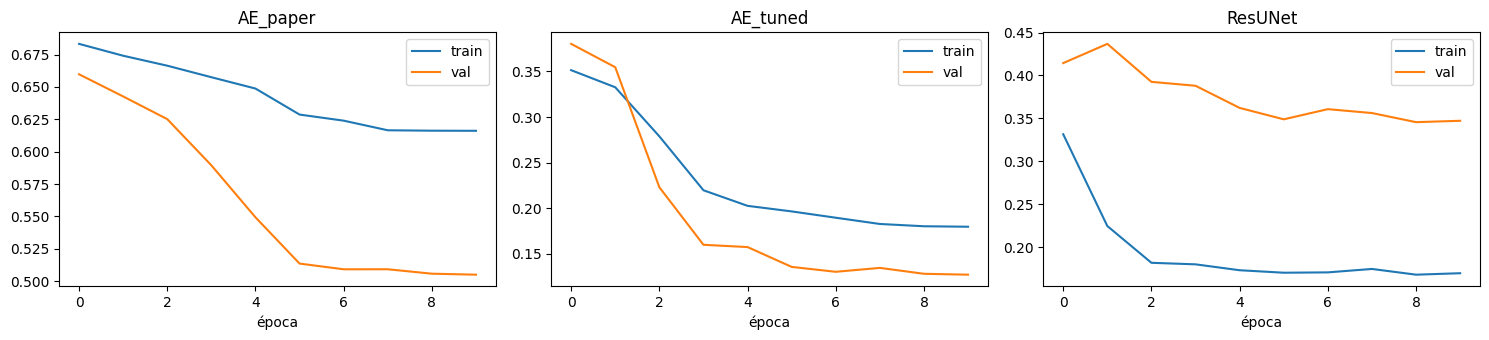

In [ ]:
# Curvas de entrenamiento
fig, axs = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (k, h) in zip(axs, histories.items()):
    ax.plot(h.history['loss'], label='train'); ax.plot(h.history['val_loss'], label='val')
    ax.set_title(k); ax.set_xlabel('época'); ax.legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/curvas_entrenamiento.png', dpi=150); plt.show()

## 7. Evaluación cuantitativa (conjunto de prueba, 512×512)

In [ ]:
models = {'AE_paper': ae_paper, 'AE_tuned': ae_tuned, 'ResUNet': unet}
preds = {k: predict_all(m, Xte) for k, m in models.items()}

res = {'Ruidosa (sin filtrar)': base}
for k, p in preds.items(): res[k] = evaluate(p, Xte_f, Yte_f)

summary = pd.DataFrame({k: v[['PSNR','SSIM','MSE','ENL_noisy','ENL_pred','ENL_gt']].mean() for k, v in res.items()}).T
# En la fila "Ruidosa", ENL_pred == ENL_noisy; ENL_gt es el valor objetivo
summary.round(4).to_csv(f'{OUT_DIR}/metricas_test.csv')
display(summary.round(3))
print("ENL objetivo (ground truth, en ROI homogénea):", round(base.ENL_gt.mean(), 2))

,PSNR,SSIM,MSE,ENL_noisy,ENL_pred,ENL_gt
Ruidosa (sin filtrar),22.172,0.543,0.007,25.992,25.992,198.828
AE_paper,25.922,0.603,0.004,25.992,543.232,198.828
AE_tuned,26.557,0.697,0.003,25.992,740.138,198.828
ResUNet,17.990,0.491,0.024,25.992,147781.915,198.828


ENL objetivo (ground truth, en ROI homogénea): 198.83


/tmp/ipykernel_12487/4140680024.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([res[k][m] for k in res], labels=list(res.keys()), showfliers=False)
/tmp/ipykernel_12487/4140680024.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([res[k][m] for k in res], labels=list(res.keys()), showfliers=False)
/tmp/ipykernel_12487/4140680024.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([res[k][m] for k in res], labels=list(res.keys()), showfliers=False)


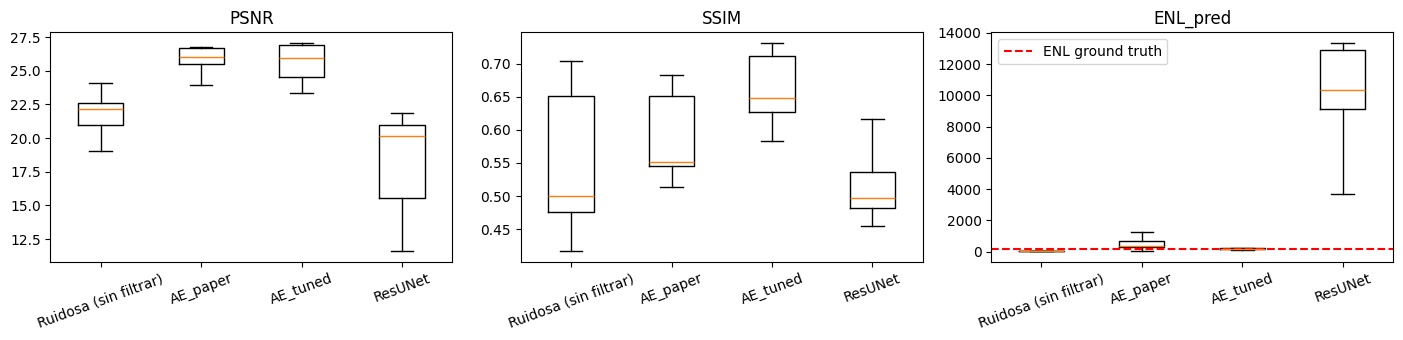

In [ ]:
# Boxplots por métrica (variabilidad entre imágenes)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, m in zip(axs, ['PSNR', 'SSIM', 'ENL_pred']):
    ax.boxplot([res[k][m] for k in res], labels=list(res.keys()), showfliers=False)
    ax.set_title(m); ax.tick_params(axis='x', rotation=20)
axs[2].axhline(base.ENL_gt.median(), color='r', ls='--', label='ENL ground truth'); axs[2].legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/boxplots_metricas.png', dpi=150); plt.show()

## 8. Validación visual

Analiza:
**1.** bordes y estructuras finas (edificios, puentes, carreteras)
**2.** artefactos (patrones en cuadrícula por `Conv2DTranspose`/`UpSampling`, halos, texturas "pintadas")
**3.** suavizado excesivo en zonas homogéneas vs. detalle perdido,
**4.** en la imagen de razón, estructura visible = detalle eliminado.

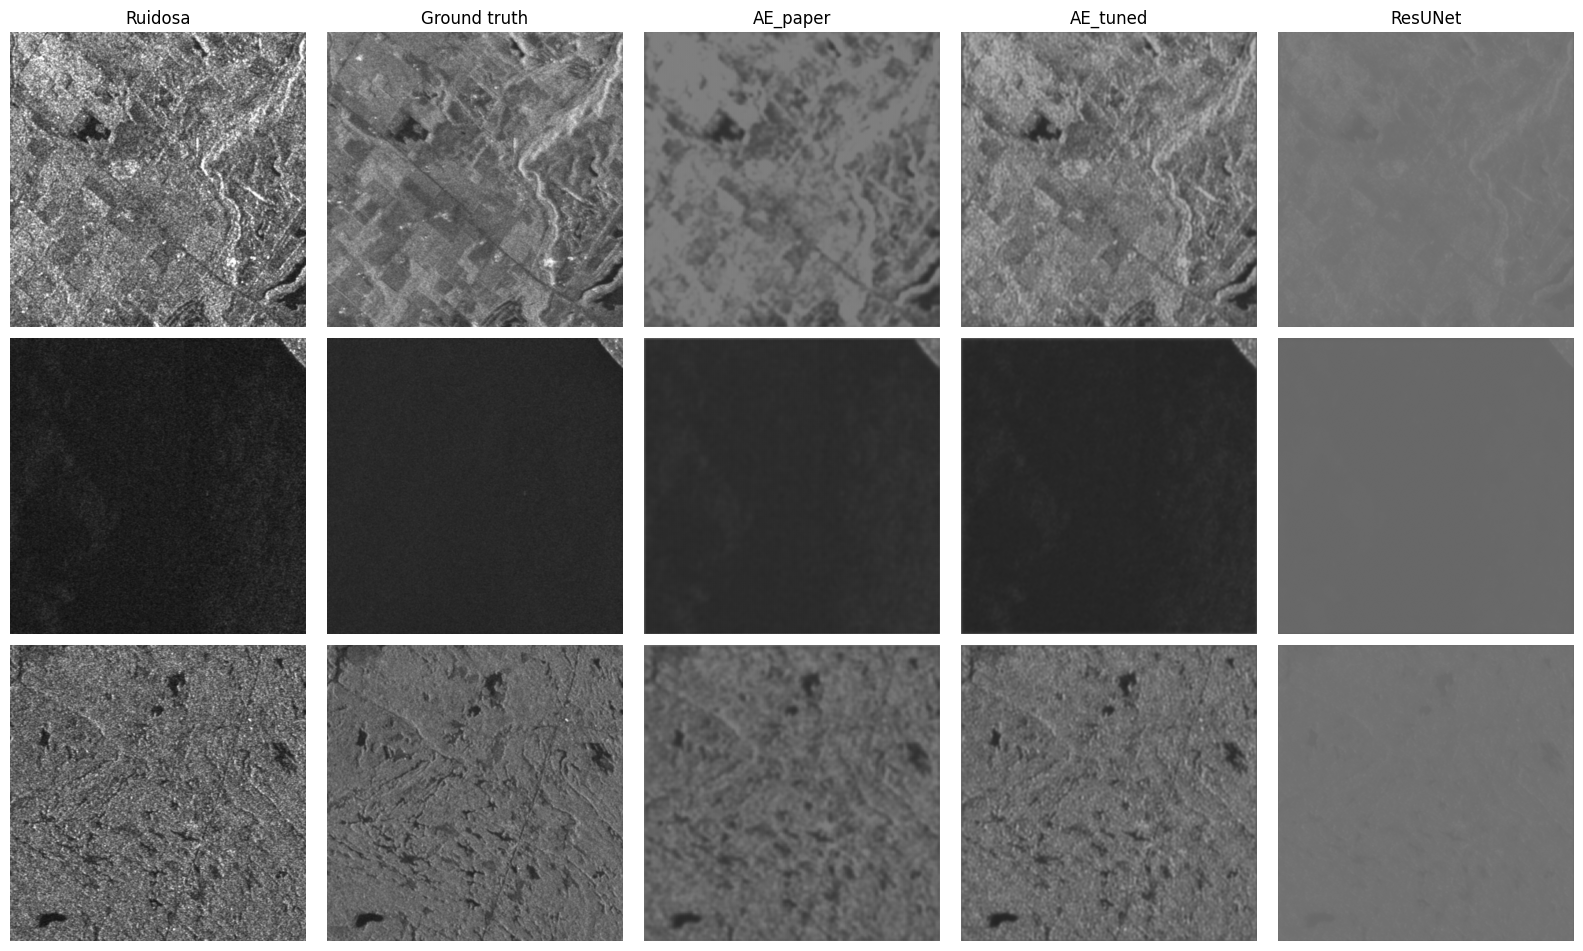

In [ ]:
def show_samples(ids, zoom=None):
    cols = ['Ruidosa', 'Ground truth'] + list(models.keys())
    fig, axs = plt.subplots(len(ids), len(cols), figsize=(3.2*len(cols), 3.2*len(ids)))
    for r, i in enumerate(ids):
        imgs = [Xte_f[i], Yte_f[i]] + [preds[k][i] for k in models]
        for c, im in enumerate(imgs):
            a = axs[r, c]; a.imshow(im[..., 0], cmap='gray', vmin=0, vmax=1); a.axis('off')
            if zoom:
                y0, x0, s = zoom; a.add_patch(plt.Rectangle((x0, y0), s, s, fill=False, ec='r', lw=1.5))
            if r == 0: a.set_title(cols[c])
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/comparacion_visual.png', dpi=150); plt.show()

def show_zoom(i, y0, x0, s=64):
    cols = ['Ruidosa', 'Ground truth'] + list(models.keys())
    imgs = [Xte_f[i], Yte_f[i]] + [preds[k][i] for k in models]
    fig, axs = plt.subplots(1, len(cols), figsize=(3*len(cols), 3.2))
    for a, im, t in zip(axs, imgs, cols):
        a.imshow(im[y0:y0+s, x0:x0+s, 0], cmap='gray', vmin=0, vmax=1, interpolation='nearest'); a.set_title(t); a.axis('off')
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/zoom_{i}_{y0}_{x0}.png', dpi=150); plt.show()

def show_ratio(ids):
    fig, axs = plt.subplots(len(ids), len(models), figsize=(3.4*len(models), 3.4*len(ids)), squeeze=False)
    for r, i in enumerate(ids):
        for c, k in enumerate(models):
            ratio = Xte_f[i,...,0] / (preds[k][i,...,0] + 1e-3)
            axs[r, c].imshow(ratio, cmap='gray', vmin=0, vmax=3); axs[r, c].axis('off')
            if r == 0: axs[r, c].set_title(f'Razón – {k}')
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/razon.png', dpi=150); plt.show()

ids = [0, 1, 2]
show_samples(ids)

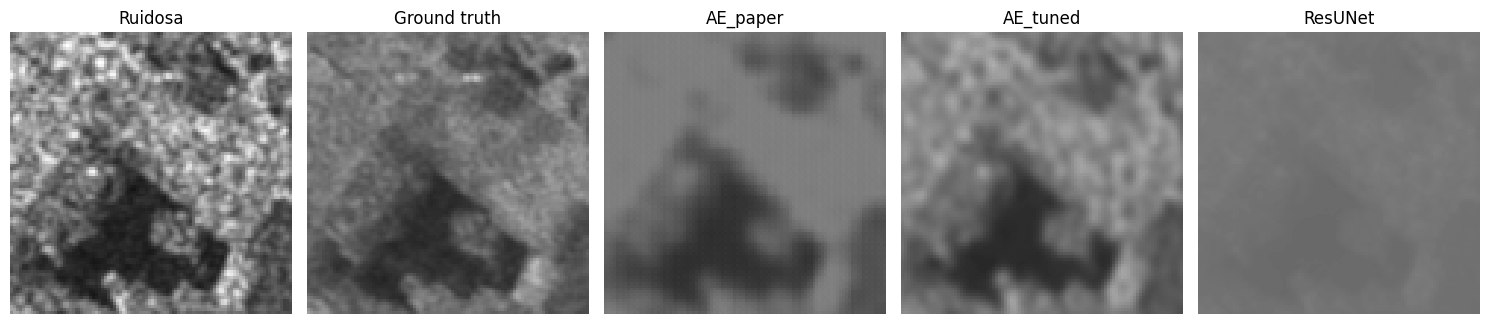

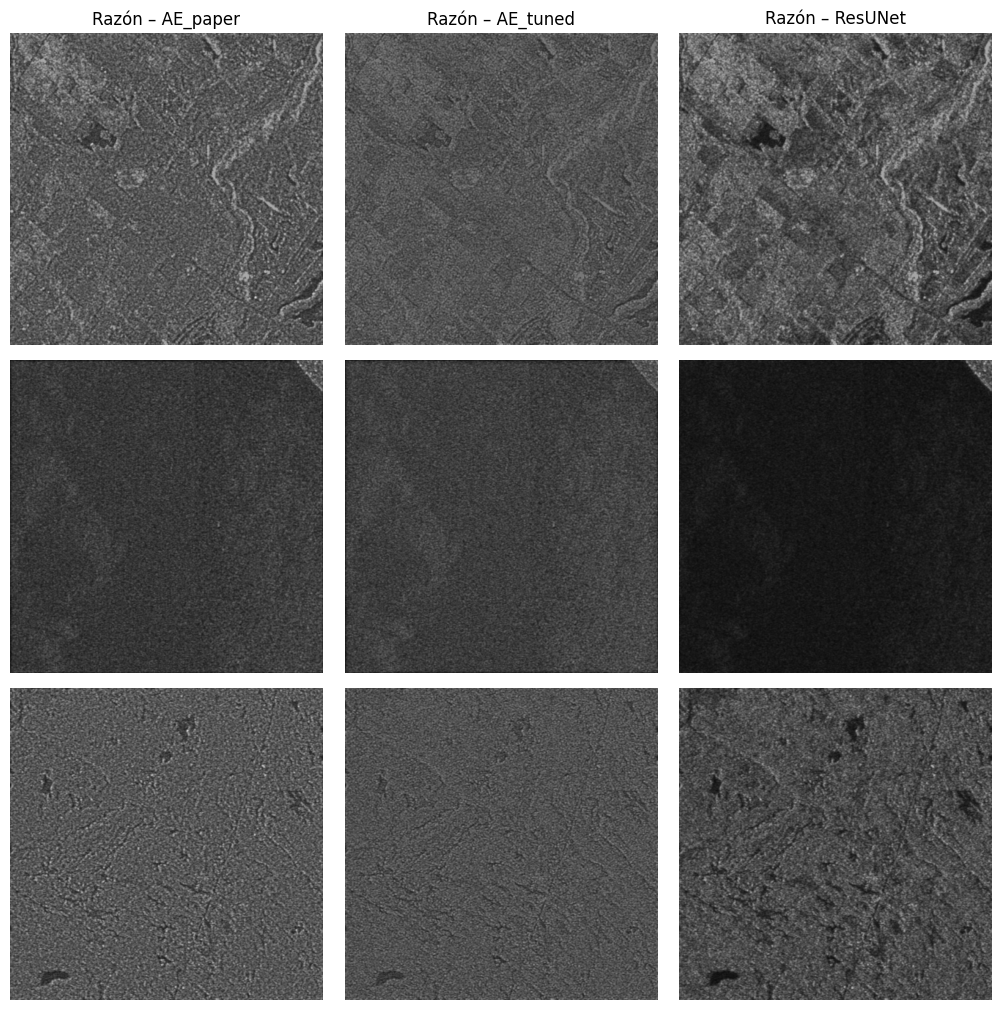

In [ ]:
# Zoom: cambia (imagen, y0, x0) para inspeccionar bordes (edificios, puentes) y zonas homogéneas
show_zoom(i=0, y0=100, x0=100, s=96)
show_ratio(ids)

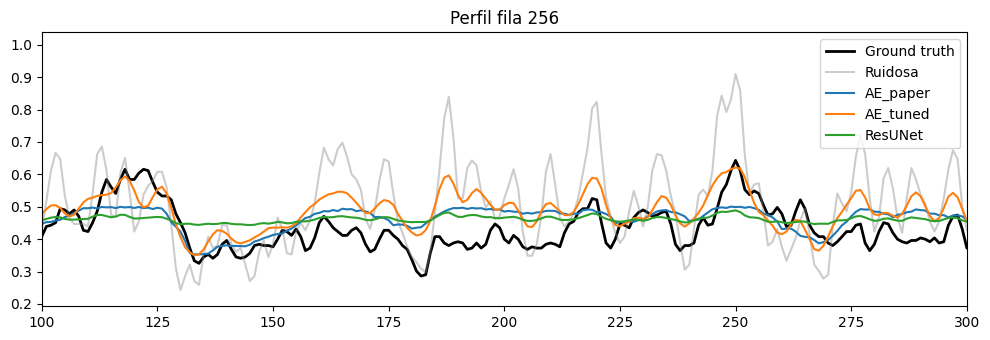

In [ ]:
# Perfil de intensidad a lo largo de una línea: ¿se conserva el borde o se emborrona?
i, row = 0, 256
plt.figure(figsize=(10, 3.5))
plt.plot(Yte_f[i, row, :, 0], 'k', lw=2, label='Ground truth')
plt.plot(Xte_f[i, row, :, 0], color='gray', alpha=.4, label='Ruidosa')
for k in models: plt.plot(preds[k][i, row, :, 0], label=k)
plt.xlim(100, 300); plt.legend(); plt.title(f'Perfil fila {row}'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/perfil_borde.png', dpi=150); plt.show()

## 9. Conclusiones
El autoencoder replicado del artículo mejora el PSNR en unos 3.7 dB y el SSIM en 0.06 sobre la imagen ruidosa. El autoencoder ajustado mejora ambos: +0.6 dB de PSNR y, sobre todo, +0.09 de SSIM respecto al AE original. La mejora en SSIM es la más relevante, porque indica mejor conservación de la estructura y no solo menor error de píxel.

2. Efecto del ajuste de hiperparámetros. De las cuatro configuraciones probadas, la mejor fue la más simple: filtros (32, 64), sin BatchNorm, con pérdida MAE + SSIM (SSIM de validación 0.789). Las tres configuraciones con BatchNorm y más filtros (64, 128) tuvieron un desempeño muy inferior (PSNR de 13–14 dB y SSIM de 0.48–0.52), aun con distinto learning rate y peso de la pérdida. Esto sugiere que, con tan pocas épocas y entrenando en recortes de 256×256 pero evaluando a 512×512, las estadísticas de BatchNorm no se estabilizaron. Es una hipótesis razonable, no algo que se haya comprobado. El cambio de pérdida (de BCE a MAE + SSIM) y la mayor capacidad frente al AE original sí aportaron mejora.

3. Análisis del ENL. El ground truth tiene un ENL de 198.8 en la región homogénea, mientras que la imagen ruidosa solo 26.0. Los autoencoders lo elevaron a 543 (AE del artículo) y 740 (AE ajustado), es decir, por encima del objetivo. Esto indica que en esa zona los filtros suavizan más que el propio promedio multitemporal, por lo que un ENL mayor no equivale a un mejor resultado. Además, la ROI es de solo 32×32 píxeles, así que esta métrica es ruidosa y debe interpretarse junto con PSNR, SSIM y la inspección visual. El ENL de 147 781 de la ResUNet no es una mejora: es consecuencia de que su salida es casi constante (varianza cercana a cero).

4. Análisis visual. El AE del artículo produce imágenes de bajo contraste y apariencia grisácea, con manchas por bloques y una textura periódica visible en las zonas homogéneas (artefactos típicos de Conv2DTranspose), además de un suavizado que borra detalle fino. El AE ajustado conserva mejor el contraste y la textura general de la escena, y se acerca más al ground truth. En las imágenes de razón se sigue viendo estructura residual (límites de parcelas, el río), lo que indica que ambos filtros eliminan parte de la información real junto con el ruido. Esa estructura es más débil en el AE ajustado, lo cual es coherente con su mejor SSIM.

5. Arquitectura no secuencial (ResUNet). La ResUNet no logró despeckling útil: sus salidas son casi uniformes y grises, sin detalle, y su PSNR (17.99 dB) y SSIM (0.491) son peores que los de la imagen ruidosa sin filtrar. La pérdida de entrenamiento bajó a 0.17, pero la de validación se quedó en 0.35, una brecha que indica un problema de generalización, y su imagen de razón conserva casi toda la estructura de la escena porque el modelo no preservó la información. La causa más probable es la combinación de pocas épocas (10 épocas de 10 pasos, unos 100 pasos de gradiente en total) con BatchNorm, que mostró el mismo problema en el estudio de hiperparámetros. Por lo tanto, este resultado no demuestra que una U-Net sea inferior a un autoencoder: solo muestra que esta implementación, con este presupuesto de entrenamiento, no convergió. Se esperaba que las skip connections preservaran bordes, pero no pudo verificarse.

6. Limitaciones. Se usaron 100 de las 1500 imágenes disponibles (80 para entrenamiento, 10 para validación y 10 para prueba) y solo 10 épocas, por restricciones de memoria y tiempo. Con un conjunto de prueba de 10 imágenes, las diferencias pequeñas entre modelos (como el 0.6 dB entre los dos autoencoders) tienen poca potencia estadística. Los datos provienen de un solo sensor y una sola escena (Toronto, Sentinel-1), por lo que no se puede asegurar que el desempeño se mantenga en otras regiones.

7. Trabajo futuro. Usar más imágenes y entrenar durante más épocas; reemplazar BatchNorm por GroupNorm (o quitarla) en la ResUNet, o entrenar y evaluar con el mismo tamaño de imagen; evaluar sobre las 100 imágenes de las carpetas Noisy_val/GTruth_val, que el modelo nunca ve; sustituir Conv2DTranspose por UpSampling más convolución para reducir los artefactos periódicos; y calcular el ENL sobre varias regiones homogéneas en lugar de una sola.
